In [68]:
# Imports
import pandas as pd

import matplotlib.pyplot as plt
plt.style.use("default")


from matplotlib import colors

import seaborn as sns

from sklearn.cluster import KMeans, DBSCAN

df = pd.read_csv("moons.csv")
df.head()

,X,Y
0,-0.415208,1.035735
1,0.058781,0.304334
2,1.109379,-0.509738
3,1.540948,-0.427550
4,0.929095,-0.532388


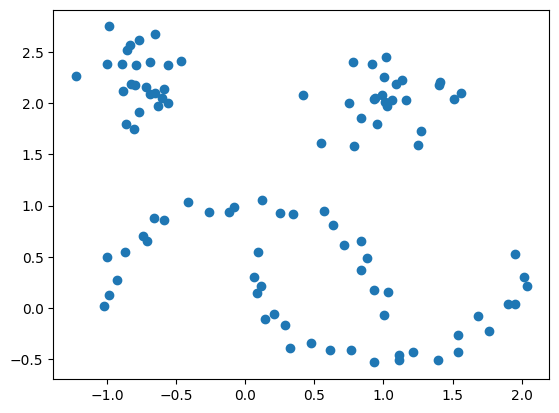

In [69]:
# Plotando os dados
plt.scatter(x=df["X"], y=df["Y"])
plt.show()

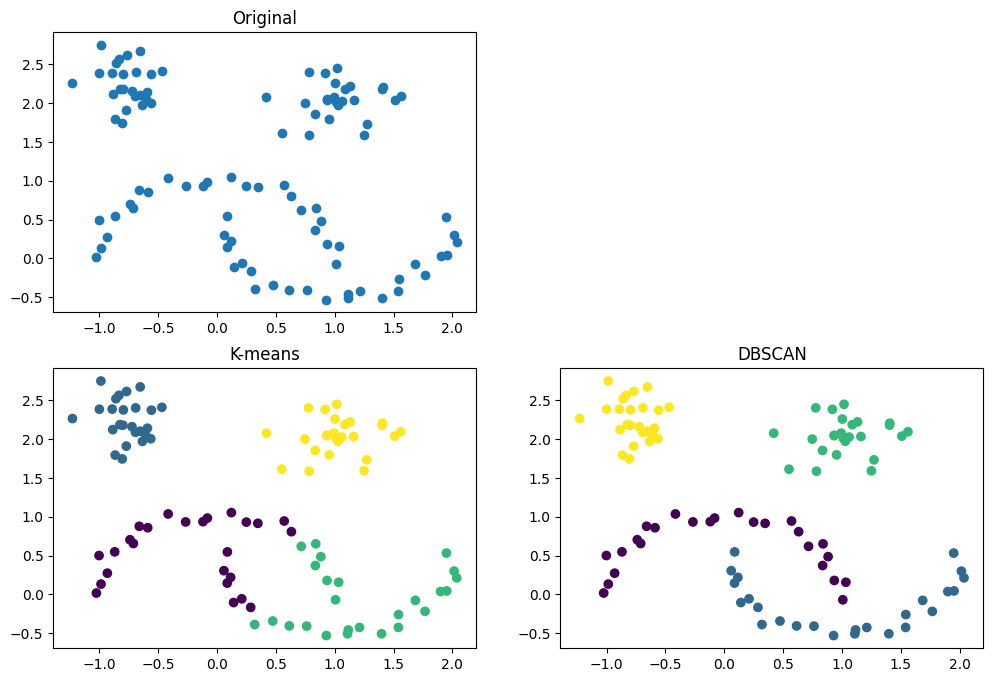

In [70]:
# Definição dos algoritmos
km = KMeans(n_clusters=4, random_state=42)
db = DBSCAN(eps=0.4)

# Aplicar os algoritmos sobre os pontos, obtendo os clusteres resultantes
c_km = km.fit_predict(df)
c_db = db.fit_predict(df)

df["label_kmeans"] = c_km
df["label_dbscan"] = c_db

# Plotando as diferenças
fig = plt.figure( figsize=(12, 8) )

plt.subplot(2, 2, 1)
plt.title("Original")
plt.scatter(x=df["X"], y=df["Y"])

plt.subplot(2, 2, 3)
plt.title("K-means")
plt.scatter(x=df["X"], y=df["Y"], c=df["label_kmeans"])

plt.subplot(2, 2, 4)
plt.title("DBSCAN")
plt.scatter(x=df["X"], y=df["Y"], c=df["label_dbscan"])

plt.show()

In [71]:
dados = pd.read_csv("mall.csv")
dados.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [72]:
dados.info()


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


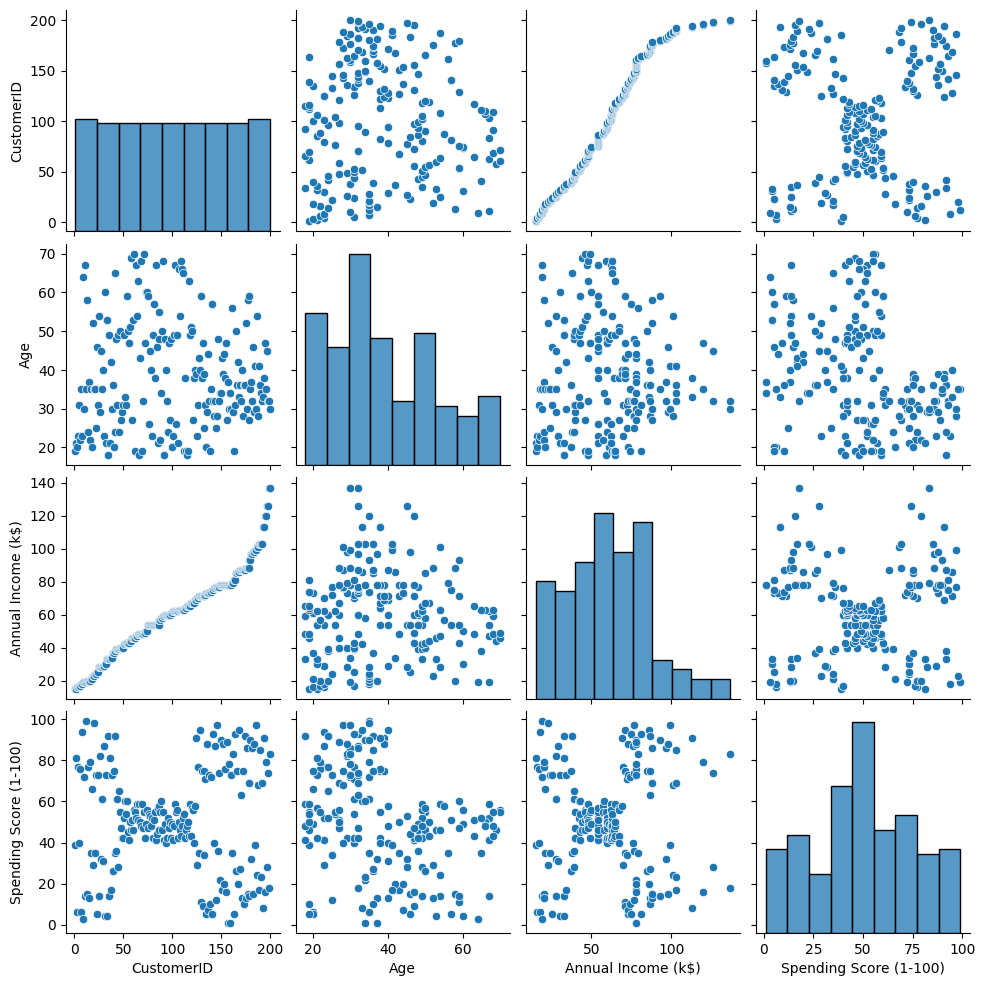

In [73]:
sns.pairplot(dados)
plt.show()


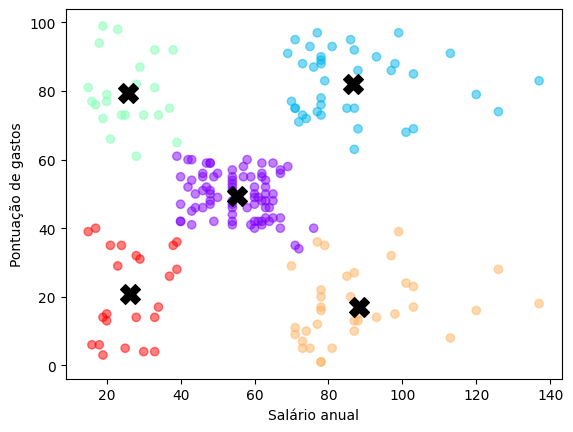

In [74]:
 ### nmormalizar os dados dependendo do caso
 # Instancia o algoritmo
kmeans = KMeans(n_clusters=5, random_state=42)

# Implementa o k-means sobre os dados
kmeans.fit( dados[ ["Annual Income (k$)", "Spending Score (1-100)"] ] )

# Obtém os centroids do método
centroids = kmeans.cluster_centers_

# Salva os labels (grupos) dos clusteres para cada exemplo
kmeans_labels = kmeans.predict( dados[ ["Annual Income (k$)",
                                        "Spending Score (1-100)"] ])

# Plotando a clusterização
plt.scatter(dados["Annual Income (k$)"],     # Eixo X
            dados["Spending Score (1-100)"], # Eixo Y
            c=kmeans_labels,                 # Esquema de cores (quantas usar)
            alpha=0.5,                       # Transparência dos pontos
            cmap="rainbow")                  # Paleta de cores
plt.xlabel("Salário anual")
plt.ylabel("Pontuação de gastos")

# Plotando os centrois
plt.scatter(centroids[:, 0],                 # Eixo X dos centroids
            centroids[:, 1],                 # Eixo Y dos centroids
            c="black",                       # Todos os centroids são pretos
            marker="X",                      # Marcação como um "X"
            s=200)                           # Tamanho da marcação

plt.show()


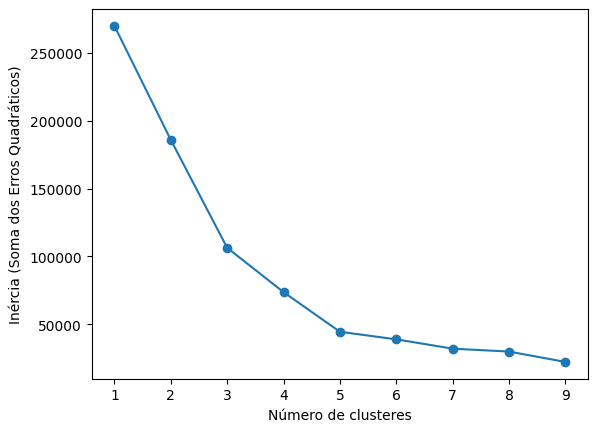

In [75]:
k = list(range(1, 10))

sse = []
for i in k:
  kmeans = KMeans(n_clusters=i, random_state=0)
  kmeans.fit( dados[ ["Annual Income (k$)", "Spending Score (1-100)"] ] )
  sse.append( kmeans.inertia_ )

plt.plot(k, sse, "-o")
plt.xlabel("Número de clusteres")
plt.ylabel("Inércia (Soma dos Erros Quadráticos)")
plt.show()

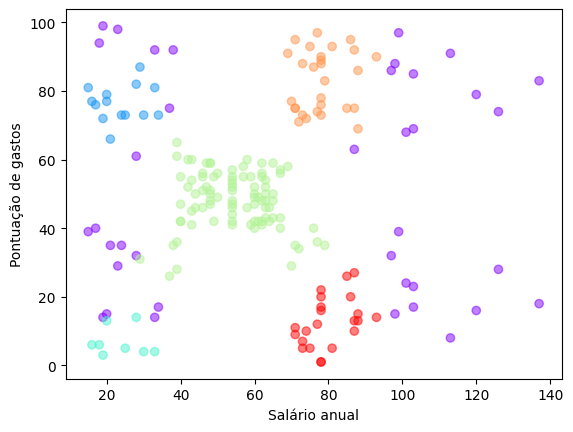

In [76]:
# Instancia o algoritmo
dbscan = DBSCAN(eps=10, min_samples=8)

# Roda o algoritmo sobre os dados
dbscan.fit( dados[ ["Annual Income (k$)", "Spending Score (1-100)"] ] )

# Obtém as atribuições dos pontos
dbscan_labels = dbscan.labels_

plt.scatter(dados["Annual Income (k$)"],     # Eixo X
            dados["Spending Score (1-100)"], # Eixo Y
            c=dbscan_labels,                 # Esquema de cores
            alpha=0.5,                       # Transparência dos pontos
            cmap="rainbow")                  # Paleta de cores
plt.xlabel("Salário anual")
plt.ylabel("Pontuação de gastos")
plt.show()

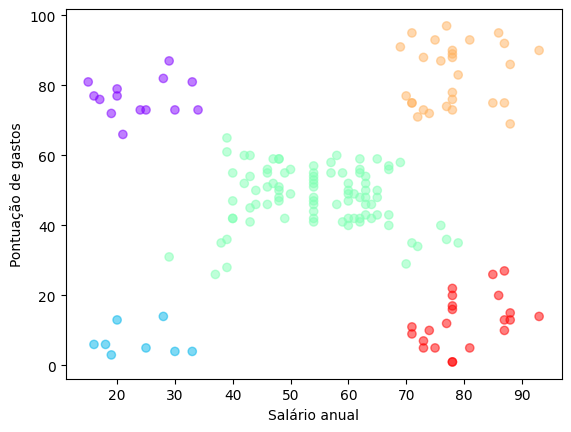

In [77]:
# Removendo os outliers (cluster "-1")
mascara = dbscan_labels >= 0

plt.scatter(dados["Annual Income (k$)"][mascara],     # Eixo X
            dados["Spending Score (1-100)"][mascara], # Eixo Y
            c=dbscan_labels[mascara],                 # Esquema de cores
            alpha=0.5,                                # Transparência dos pontos
            cmap="rainbow")                           # Paleta de cores
plt.xlabel("Salário anual")
plt.ylabel("Pontuação de gastos")
plt.show()

In [78]:
dados['kmeans'] = kmeans_labels # Salva os clusters do K-Means no DataFrame
dados['dbscan'] = dbscan_labels # Salva os clusters do DBSCAN no DataFrame

In [79]:
dados[ dados["kmeans"] == 2 ].describe() # ganha pouco e gasta pouco

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),kmeans,dbscan
count,22.000000,22.000000,22.000000,22.000000,22.0,22.000000
mean,23.090909,25.272727,25.727273,79.363636,2.0,-0.227273
std,13.147185,5.257030,7.566731,10.504174,0.0,0.685344
min,2.000000,18.000000,15.000000,61.000000,2.0,-1.000000
25%,12.500000,21.250000,19.250000,73.000000,2.0,-1.000000
50%,23.000000,23.500000,24.500000,77.000000,2.0,0.000000
75%,33.500000,29.750000,32.250000,85.750000,2.0,0.000000
max,46.000000,35.000000,39.000000,99.000000,2.0,2.000000


In [80]:
dados[ dados["kmeans"] == 4 ].describe() # ganha bem e gasta muito

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),kmeans,dbscan
count,23.00000,23.000000,23.000000,23.000000,23.0,23.000000
mean,23.00000,45.217391,26.304348,20.913043,4.0,0.347826
std,13.56466,13.228607,7.893811,13.017167,0.0,1.265224
min,1.00000,19.000000,15.000000,3.000000,4.0,-1.000000
25%,12.00000,35.500000,19.500000,9.500000,4.0,-1.000000
50%,23.00000,46.000000,25.000000,17.000000,4.0,1.000000
75%,34.00000,53.500000,33.000000,33.500000,4.0,1.000000
max,45.00000,67.000000,39.000000,40.000000,4.0,2.000000


In [81]:
# Importando as bibliotecas necessárias
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

# Carregar os dados (substitua pelo caminho do seu dataset)
crop_yield_data = pd.read_csv("crop_yield.csv")

# Converter dados categóricos em valores numéricos usando one-hot encoding
crop_yield_data = pd.get_dummies(crop_yield_data,
                                 columns=['Crop'],
                                 prefix=['Crop'],
                                 drop_first=True)

# Supondo que a coluna 'yield' é a variável dependente (target)
# Separar os dados em X (features) e y (target)
X = crop_yield_data.drop(columns=['Yield'])
y = crop_yield_data['Yield']

# Dividir os dados em conjuntos de treino e teste
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42)

# Escalar os dados
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Modelo de Regressão Linear sem PCA
regressor = LinearRegression()
regressor.fit(X_train_scaled, y_train)

# Prever e calcular o erro (sem PCA)
y_pred_no_pca = regressor.predict(X_test_scaled)
mse_no_pca = mean_squared_error(y_test, y_pred_no_pca)
print(f"Erro Quadrático Médio sem PCA: {mse_no_pca}")

# Aplicar PCA para reduzir a dimensionalidade antes do treinamento
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Modelo de Regressão Linear com PCA
regressor_pca = LinearRegression()
regressor_pca.fit(X_train_pca, y_train)

# Prever e calcular o erro (com PCA)
y_pred_pca = regressor_pca.predict(X_test_pca)
mse_with_pca = mean_squared_error(y_test, y_pred_pca)
print(f"Erro Quadrático Médio com PCA: {mse_with_pca}")

# Comparando os resultados
if mse_no_pca < mse_with_pca:
    print("O modelo sem PCA teve um desempenho melhor.")
else:
    print("O modelo com PCA teve um desempenho melhor.")

Erro Quadrático Médio sem PCA: 19308693.244843204
Erro Quadrático Médio com PCA: 4115043128.0440187
O modelo sem PCA teve um desempenho melhor.
